In [1]:
# INDUSTRIAL ANOMALY DETECTION
# DATA UNDERSTANDING

from pathlib import Path

import pandas as pd
import numpy as np
import pyreadr
import matplotlib.pyplot as plt
import seaborn as sns

# Project directory
PROJECT_ROOT = Path.cwd().parent

# Dataset directory
DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "TEP_FaultFree_Training.RData"
)

# Report directory
REPORTS_PATH = PROJECT_ROOT / "reports"
REPORTS_PATH.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_ROOT)
print("Dataset exists:", DATA_PATH.exists())
print("Research environment ready!")

Project directory: c:\Users\CDT WO AZEEZ SAMAD\Downloads\industrial_anomaly_detection
Dataset exists: True
Research environment ready!


In [2]:
# Load fault-free training data

result = pyreadr.read_r(str(DATA_PATH))

df = result["fault_free_training"]

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (250000, 55)


,faultNumber,simulationRun,sample,xmeas_1,xmeas_2,xmeas_3,xmeas_4,xmeas_5,xmeas_6,xmeas_7,...,xmv_2,xmv_3,xmv_4,xmv_5,xmv_6,xmv_7,xmv_8,xmv_9,xmv_10,xmv_11
0,0.0,1.0,1,0.25038,3674.0,4529.0,9.2320,26.889,42.402,2704.3,...,53.744,24.657,62.544,22.137,39.935,42.323,47.757,47.510,41.258,18.447
1,0.0,1.0,2,0.25109,3659.4,4556.6,9.4264,26.721,42.576,2705.0,...,53.414,24.588,59.259,22.084,40.176,38.554,43.692,47.427,41.359,17.194
2,0.0,1.0,3,0.25038,3660.3,4477.8,9.4426,26.875,42.070,2706.2,...,54.357,24.666,61.275,22.380,40.244,38.990,46.699,47.468,41.199,20.530
3,0.0,1.0,4,0.24977,3661.3,4512.1,9.4776,26.758,42.063,2707.2,...,53.946,24.725,59.856,22.277,40.257,38.072,47.541,47.658,41.643,18.089
4,0.0,1.0,5,0.29405,3679.0,4497.0,9.3381,26.889,42.650,2705.1,...,53.658,28.797,60.717,21.947,39.144,41.955,47.645,47.346,41.507,18.461


In [3]:
# Separate metadata from process variables

metadata_columns = [
    "faultNumber",
    "simulationRun",
    "sample"
]

feature_columns = [
    col for col in df.columns
    if col.startswith("xmeas_")
    or col.startswith("xmv_")
]

X_normal = df[feature_columns].copy()

print("Metadata columns:", len(metadata_columns))
print("Process variables:", len(feature_columns))

print("\nMeasurement variables:",
      len([c for c in feature_columns if c.startswith("xmeas_")]))

print("Manipulated variables:",
      len([c for c in feature_columns if c.startswith("xmv_")]))

X_normal.head()

Metadata columns: 3
Process variables: 52

Measurement variables: 41
Manipulated variables: 11


,xmeas_1,xmeas_2,xmeas_3,xmeas_4,xmeas_5,xmeas_6,xmeas_7,xmeas_8,xmeas_9,xmeas_10,...,xmv_2,xmv_3,xmv_4,xmv_5,xmv_6,xmv_7,xmv_8,xmv_9,xmv_10,xmv_11
0,0.25038,3674.0,4529.0,9.2320,26.889,42.402,2704.3,74.863,120.41,0.33818,...,53.744,24.657,62.544,22.137,39.935,42.323,47.757,47.510,41.258,18.447
1,0.25109,3659.4,4556.6,9.4264,26.721,42.576,2705.0,75.000,120.41,0.33620,...,53.414,24.588,59.259,22.084,40.176,38.554,43.692,47.427,41.359,17.194
2,0.25038,3660.3,4477.8,9.4426,26.875,42.070,2706.2,74.771,120.42,0.33563,...,54.357,24.666,61.275,22.380,40.244,38.990,46.699,47.468,41.199,20.530
3,0.24977,3661.3,4512.1,9.4776,26.758,42.063,2707.2,75.224,120.39,0.33553,...,53.946,24.725,59.856,22.277,40.257,38.072,47.541,47.658,41.643,18.089
4,0.29405,3679.0,4497.0,9.3381,26.889,42.650,2705.1,75.388,120.39,0.32632,...,53.658,28.797,60.717,21.947,39.144,41.955,47.645,47.346,41.507,18.461


# 4. Exploratory Data Analysis

## 4.1 Simulation Run Analysis

The fault-free training dataset contains 500 independent
simulation runs, with 500 observations per run.

This section examines the structure of the simulation runs
and the distribution of process variables under normal
operating conditions.

In [4]:
# Examine simulation run distribution

run_counts = df.groupby("simulationRun").size()

print("Number of simulation runs:", run_counts.shape[0])
print("Minimum observations:", run_counts.min())
print("Maximum observations:", run_counts.max())
print("Average observations:", run_counts.mean())

run_counts.describe()

Number of simulation runs: 500
Minimum observations: 500
Maximum observations: 500
Average observations: 500.0


count    500.0
mean     500.0
std        0.0
min      500.0
25%      500.0
50%      500.0
75%      500.0
max      500.0
dtype: float64

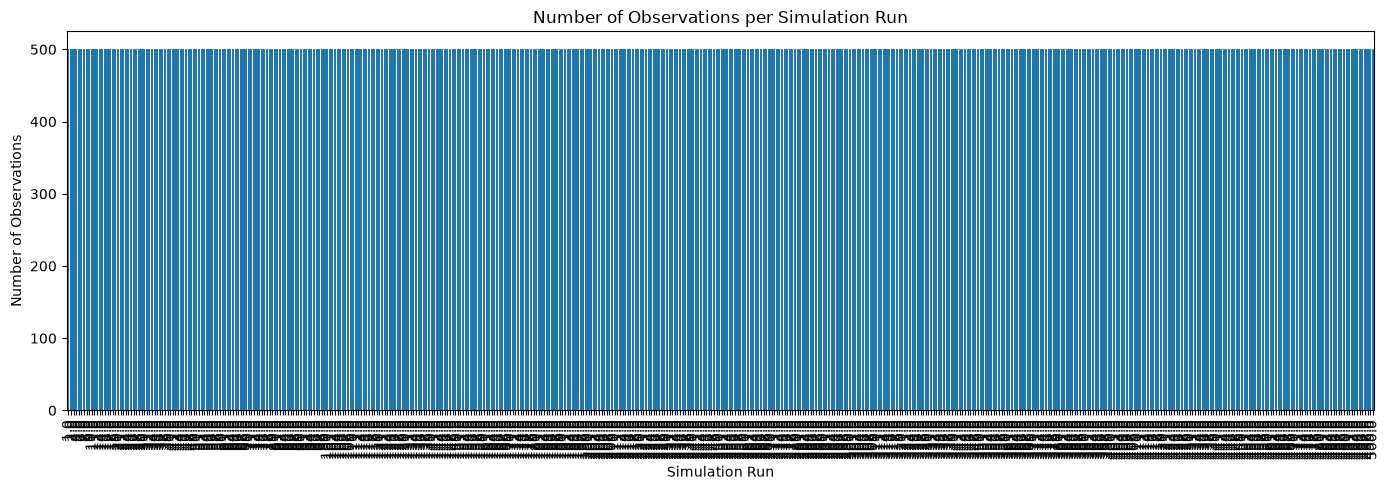

In [5]:
# Visualise observations per run
plt.figure(figsize=(14, 5))

run_counts.plot(kind="bar", width=0.8)

plt.title("Number of Observations per Simulation Run")
plt.xlabel("Simulation Run")
plt.ylabel("Number of Observations")
plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

In [6]:
# Examine descriptive statistics
# Generate descriptive statistics for all process variables

descriptive_stats = X_normal.describe().T

descriptive_stats["variance"] = X_normal.var()

descriptive_stats.round(3)

,count,mean,std,min,25%,50%,75%,max,variance
xmeas_1,250000.0,0.250,0.031,0.122,0.230,0.251,0.271,0.392,0.001
xmeas_2,250000.0,3663.786,34.006,3511.800,3640.800,3663.700,3686.800,3808.400,1156.432
xmeas_3,250000.0,4508.820,39.215,4336.900,4482.400,4508.800,4535.300,4683.700,1537.849
xmeas_4,250000.0,9.347,0.086,8.973,9.289,9.347,9.405,9.730,0.007
xmeas_5,250000.0,26.902,0.211,25.951,26.758,26.902,27.046,27.818,0.045
xmeas_6,250000.0,42.338,0.219,41.394,42.188,42.338,42.487,43.257,0.048
xmeas_7,250000.0,2705.038,7.526,2672.300,2700.100,2705.000,2710.000,2739.100,56.635
xmeas_8,250000.0,75.000,0.542,72.649,74.632,75.000,75.369,77.514,0.294
xmeas_9,250000.0,120.400,0.019,120.310,120.390,120.400,120.410,120.480,0.000
xmeas_10,250000.0,0.337,0.013,0.285,0.329,0.337,0.346,0.395,0.000


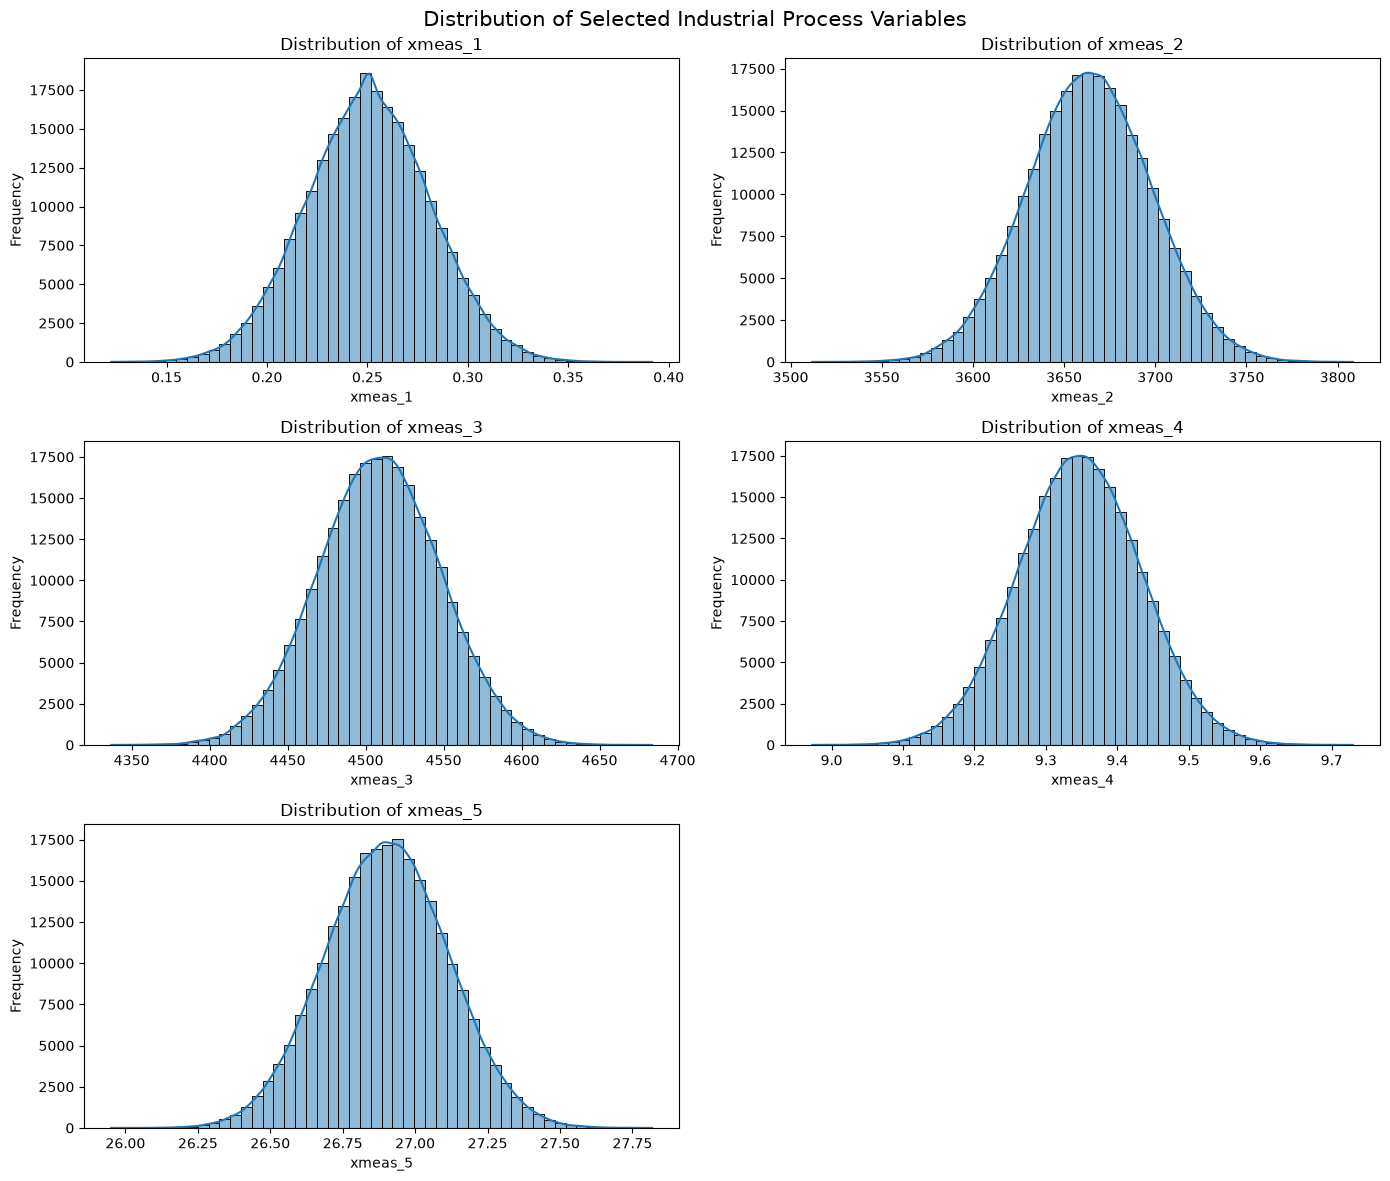

In [7]:
# Visualise selected process variables

selected_features = [
    "xmeas_1",
    "xmeas_2",
    "xmeas_3",
    "xmeas_4",
    "xmeas_5"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

axes = axes.flatten()

for i, feature in enumerate(selected_features):

    sns.histplot(
        data=X_normal,
        x=feature,
        bins=50,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(
        f"Distribution of {feature}"
    )

    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Frequency")

axes[-1].axis("off")

plt.suptitle(
    "Distribution of Selected Industrial Process Variables",
    fontsize=15
)

plt.tight_layout()
plt.show()

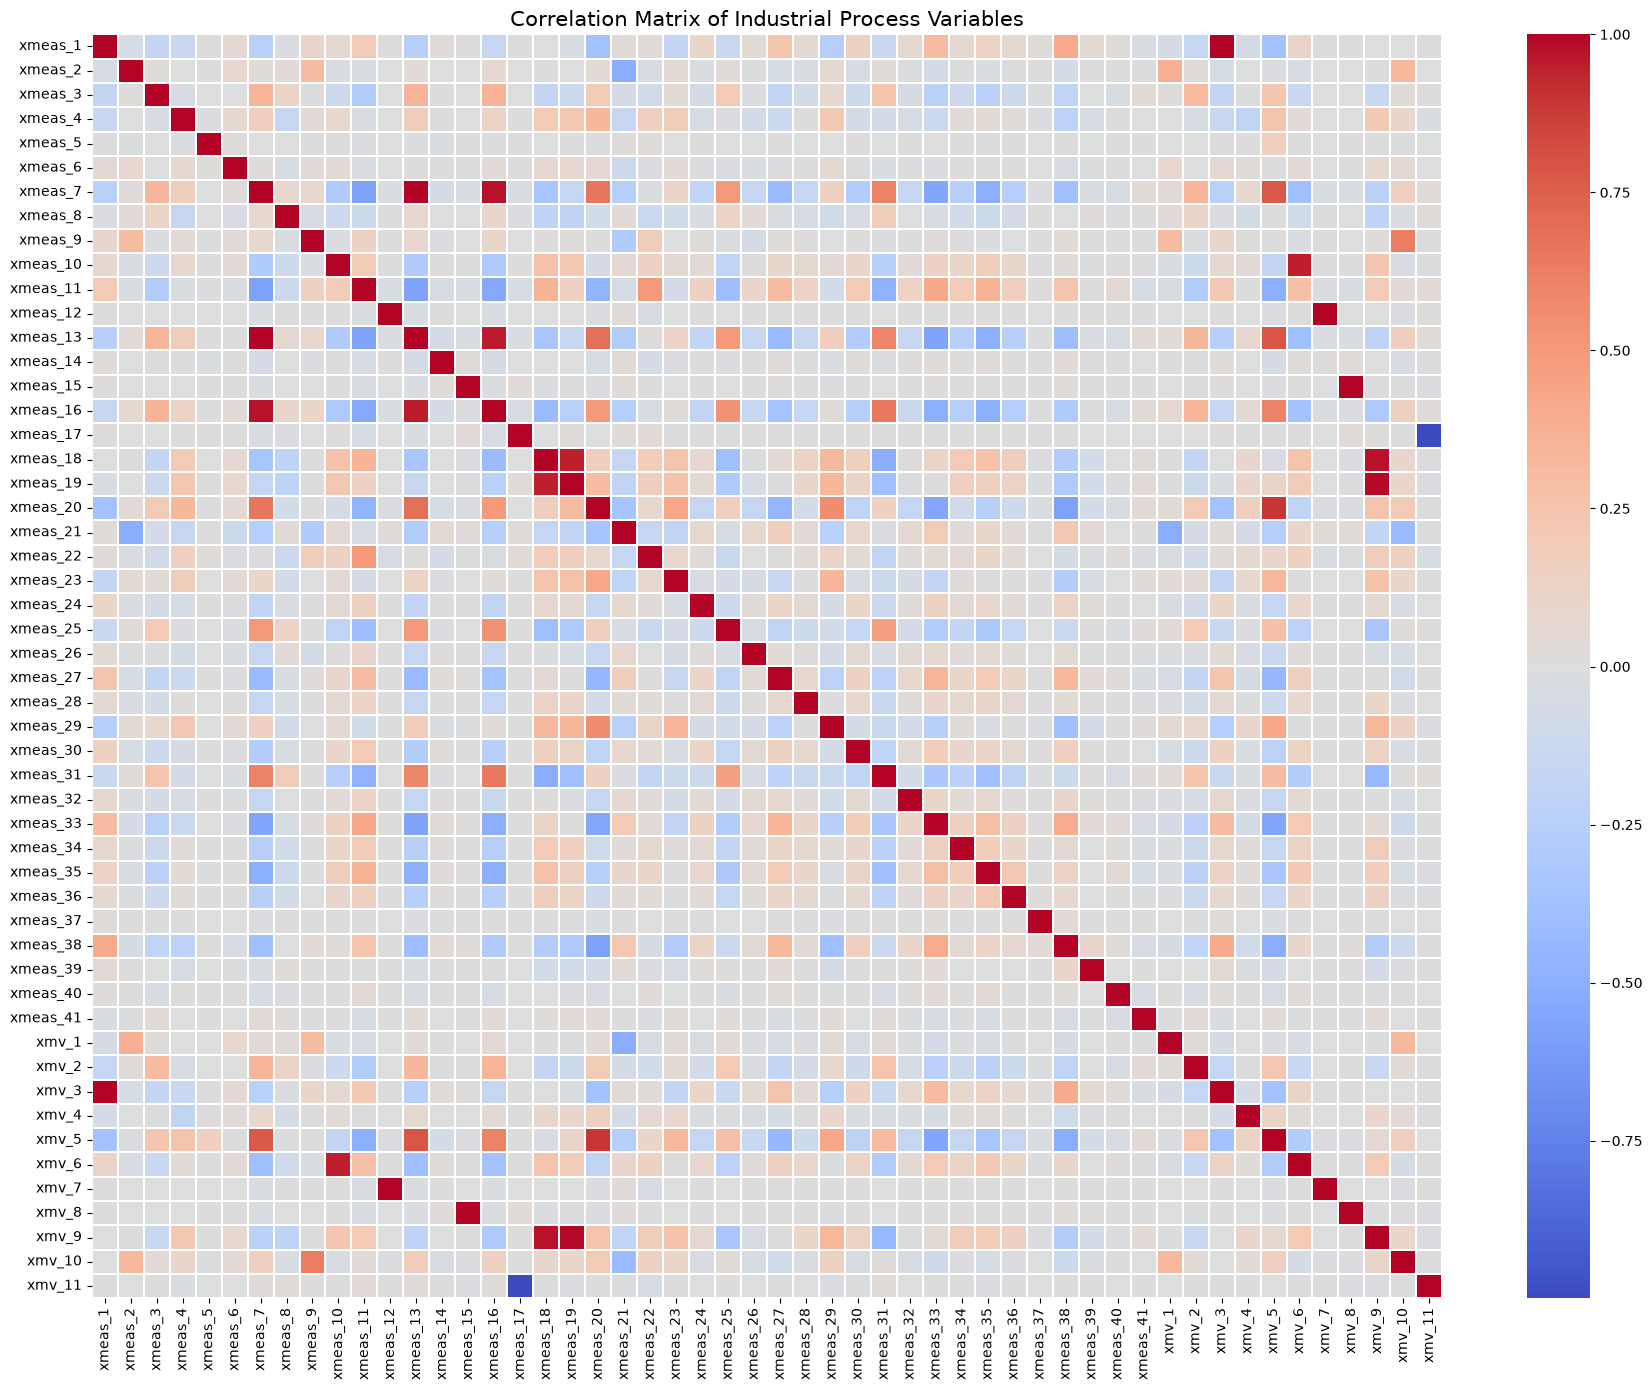

In [8]:
# Examine relationships between variables

correlation_matrix = X_normal.corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.1,
    cbar=True
)

plt.title(
    "Correlation Matrix of Industrial Process Variables",
    fontsize=15
)

plt.tight_layout()
plt.show()

## 4.2 Temporal Behaviour of Process Variables

The dataset contains sequential observations collected during
industrial process simulations.

This section examines how selected process variables change
over time within an individual simulation run.

Simulation Run 1 is selected for this initial investigation.

In [9]:
# Select simulation run 1

run_1 = (
    df[df["simulationRun"] == 1]
    .sort_values("sample")
    .copy()
)

print("Simulation Run:", run_1["simulationRun"].iloc[0])
print("Number of observations:", len(run_1))

run_1.head()

Simulation Run: 1.0
Number of observations: 500


,faultNumber,simulationRun,sample,xmeas_1,xmeas_2,xmeas_3,xmeas_4,xmeas_5,xmeas_6,xmeas_7,...,xmv_2,xmv_3,xmv_4,xmv_5,xmv_6,xmv_7,xmv_8,xmv_9,xmv_10,xmv_11
0,0.0,1.0,1,0.25038,3674.0,4529.0,9.2320,26.889,42.402,2704.3,...,53.744,24.657,62.544,22.137,39.935,42.323,47.757,47.510,41.258,18.447
1,0.0,1.0,2,0.25109,3659.4,4556.6,9.4264,26.721,42.576,2705.0,...,53.414,24.588,59.259,22.084,40.176,38.554,43.692,47.427,41.359,17.194
2,0.0,1.0,3,0.25038,3660.3,4477.8,9.4426,26.875,42.070,2706.2,...,54.357,24.666,61.275,22.380,40.244,38.990,46.699,47.468,41.199,20.530
3,0.0,1.0,4,0.24977,3661.3,4512.1,9.4776,26.758,42.063,2707.2,...,53.946,24.725,59.856,22.277,40.257,38.072,47.541,47.658,41.643,18.089
4,0.0,1.0,5,0.29405,3679.0,4497.0,9.3381,26.889,42.650,2705.1,...,53.658,28.797,60.717,21.947,39.144,41.955,47.645,47.346,41.507,18.461


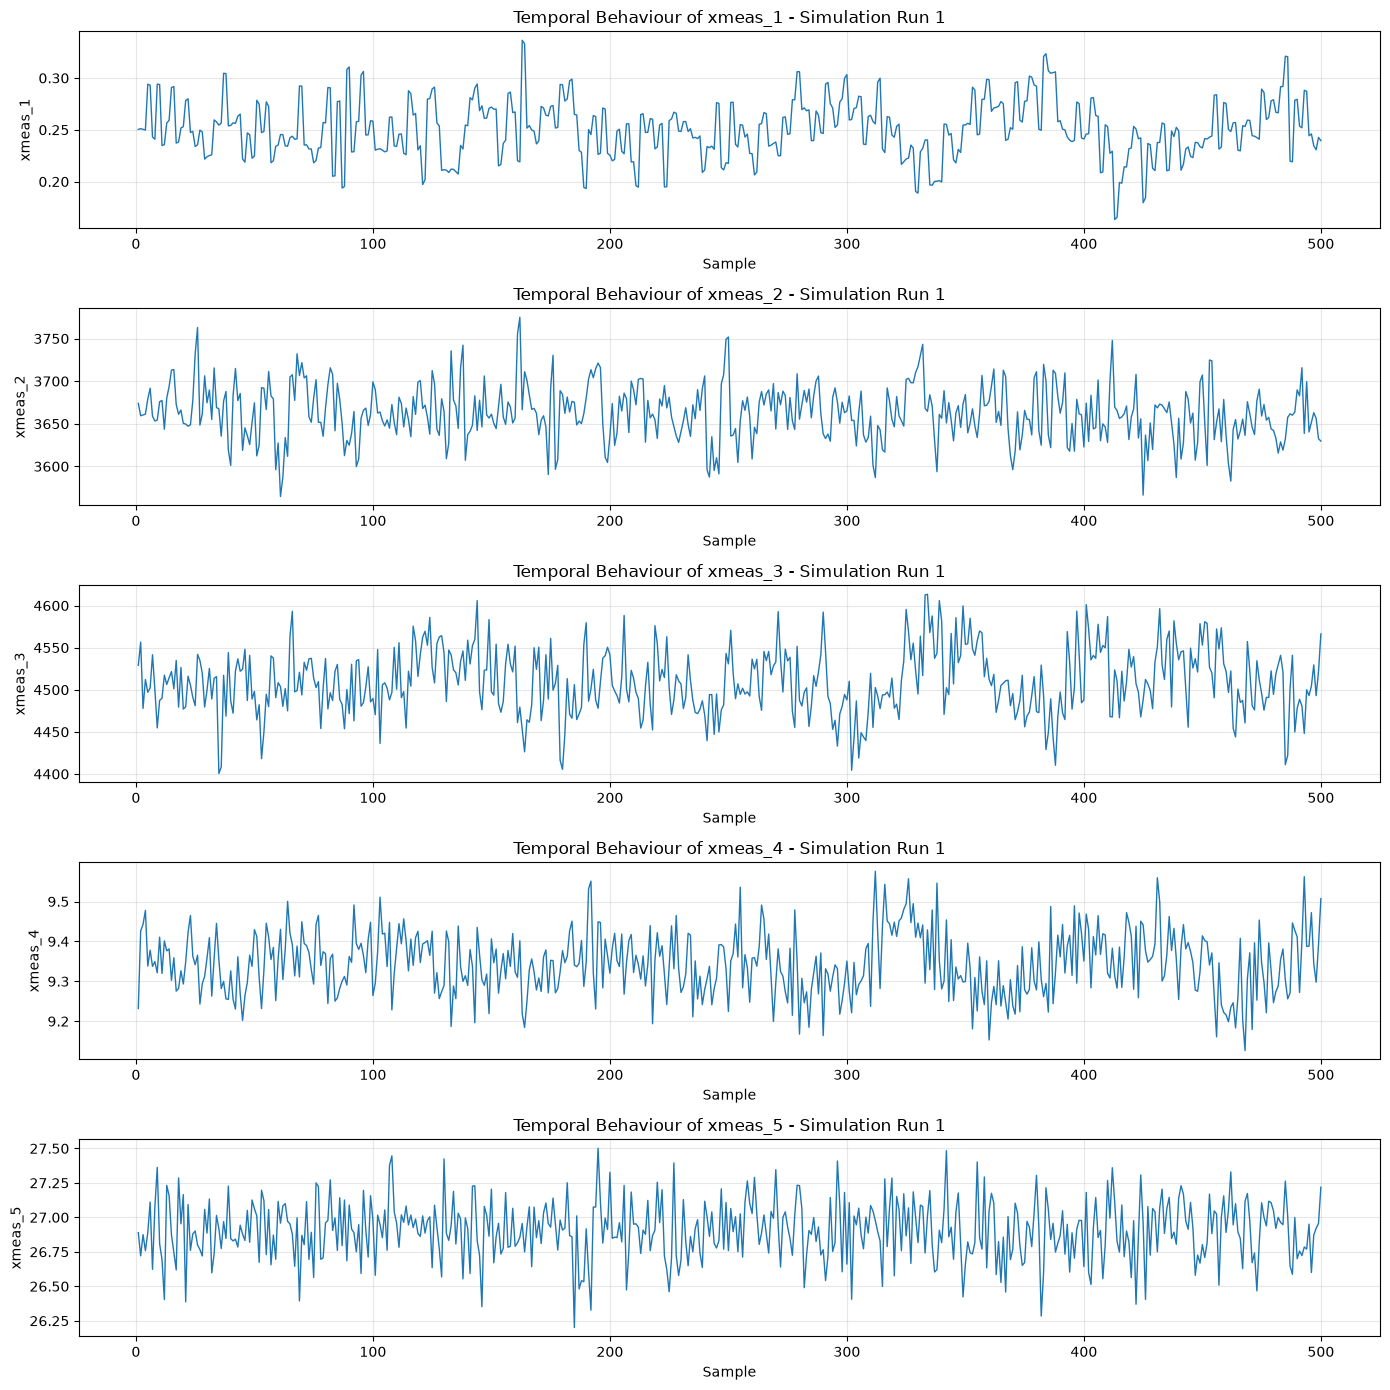

In [10]:
# Visualise changes over time

selected_features = [
    "xmeas_1",
    "xmeas_2",
    "xmeas_3",
    "xmeas_4",
    "xmeas_5"
]

fig, axes = plt.subplots(
    len(selected_features),
    1,
    figsize=(14, 14)
)

for i, feature in enumerate(selected_features):

    axes[i].plot(
        run_1["sample"],
        run_1[feature],
        linewidth=1
    )

    axes[i].set_title(
        f"Temporal Behaviour of {feature} - Simulation Run 1"
    )

    axes[i].set_xlabel("Sample")
    axes[i].set_ylabel(feature)
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
# Identify the strongest variable relationships

# Calculate feature correlations

correlation_matrix = X_normal.corr()

# Extract only the upper triangle to avoid duplicate pairs

upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

# Identify the 15 strongest absolute correlations

strongest_correlations = (
    upper_triangle.stack()
    .rename("correlation")
    .reset_index()
)

strongest_correlations.columns = [
    "feature_1",
    "feature_2",
    "correlation"
]

strongest_correlations["absolute_correlation"] = (
    strongest_correlations["correlation"].abs()
)

strongest_correlations = (
    strongest_correlations
    .sort_values(
        "absolute_correlation",
        ascending=False
    )
    .head(15)
)

strongest_correlations

,feature_1,feature_2,correlation,absolute_correlation
619,xmeas_12,xmv_7,1.000000,1.000000
776,xmeas_15,xmv_8,1.000000,1.000000
883,xmeas_17,xmv_11,-0.999243,0.999243
324,xmeas_7,xmeas_13,0.997386,0.997386
43,xmeas_1,xmv_3,0.996587,0.996587
985,xmeas_19,xmv_9,0.986063,0.986063
933,xmeas_18,xmv_9,0.970133,0.970133
327,xmeas_7,xmeas_16,0.969467,0.969467
639,xmeas_13,xmeas_16,0.959764,0.959764
902,xmeas_18,xmeas_19,0.949616,0.949616


## 4.3 Preliminary EDA Findings

The exploratory analysis of the fault-free training dataset
revealed the following characteristics:

1. The dataset contains 250,000 observations distributed
   across 500 simulation runs.

2. Each simulation run contains exactly 500 observations,
   indicating a consistent structure in the training data.

3. No missing feature values or exact duplicate observations
   were identified during the initial profiling.

4. The five selected process variables exhibit broadly
   unimodal and approximately bell-shaped distributions.

5. The process variables have different numerical scales,
   indicating the need to investigate feature scaling before
   applying distance-based machine learning algorithms.

6. The correlation heatmap indicates relationships among
   certain process variables. These relationships will be
   considered during model development and interpretation.

Further temporal analysis is required to understand how
process measurements fluctuate during normal operation.